In [39]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.ticker as ticker
from scipy.interpolate import make_interp_spline as mis

In [40]:
C0 = 1.007
C = [0, 0, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
for i in range(3, 12):
    C[i]+=C0
Texp = [0, 0, 0, 91.2, 112, 127, 141, 154, 168, 178, 188, 199]
Tth = list(map(lambda x: float(2*np.pi*np.sqrt(0.1*x*(10**(-9)))*(10**6)), C))
print(Tth)

[0.0, 0.0, 0.0, 89.01302384030404, 108.954853832357, 125.77361382287631, 140.59460762953097, 153.99573193740633, 166.32055560084342, 177.79305097727809, 188.56884879598948, 198.76129526816956]


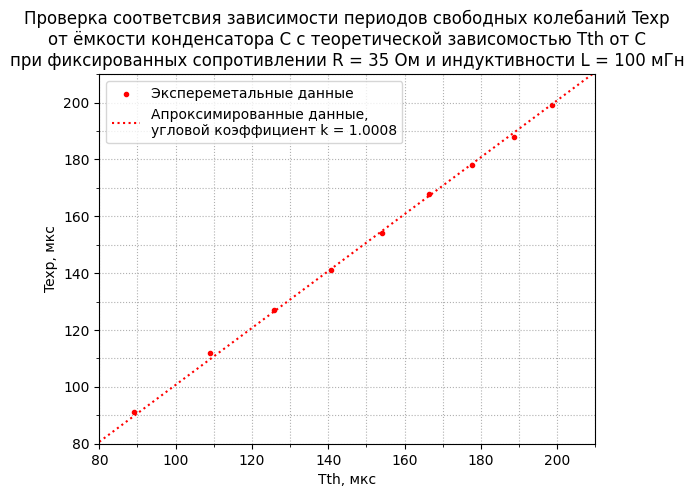

In [41]:
ax = plt.gca()
plt.scatter(Tth, Texp, marker='.', label='Экспереметальные данные', color='red')
coeffs = np.polyfit(Tth, Texp, deg=1)
poly_func = np.poly1d(coeffs)
x = np.linspace(80, 210, 100)
y = poly_func(x)
plt.plot(x, y, label=f"Апроксимированные данные,\nугловой коэффициент k = {coeffs[0]:.4f}", color='red', ls=':',)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(10))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(10))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(80, 210)
plt.xlim(80, 210)
plt.title('Проверка соответсвия зависимости периодов свободных колебаний Texp\nот ёмкости конденсатора C с теоретической зависомостью Tth от C\nпри фиксированных сопротивлении R = 35 Ом и индуктивности L = 100 мГн')
plt.xlabel("Tth, мкс")
plt.ylabel("Texp, мкс")
ax.legend()
plt.show()

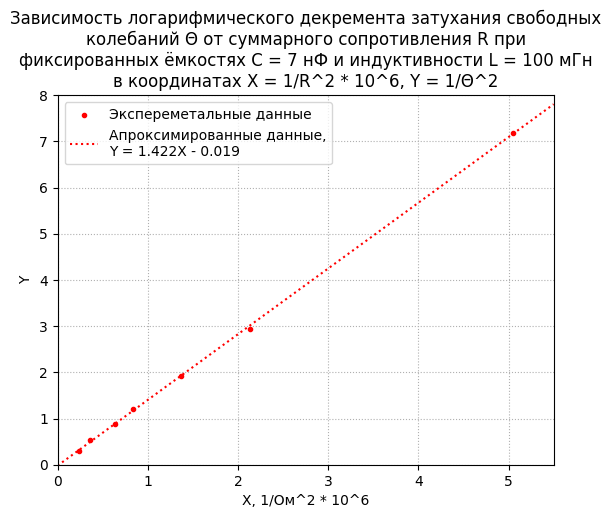

In [42]:
Rl = 35
R = [410, 650, 820, 1060, 1220, 1630, 2040]
d = [0.373, 0.584, 0.72, 0.909, 1.069, 1.365, 1.867]
for i in range(7):
    R[i]+=Rl
X = list(map(lambda x: 1/(x**2)*10**6, R))
Y = list(map(lambda x: 1/(x**2), d))
ax = plt.gca()
plt.scatter(X, Y, marker='.', label='Экспереметальные данные', color='red')
coeffs = np.polyfit(X, Y, deg=1)
poly_func = np.poly1d(coeffs)
x = np.linspace(0, 5.5, 100)
y = poly_func(x)
plt.plot(x, y, label=f"Апроксимированные данные,\nY = {coeffs[0]:.3f}X - {abs(coeffs[1]):.3f}", color='red', ls=':',)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(10))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(10))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(0, 8)
plt.xlim(0, 5.5)
plt.title('Зависимость логарифмического декремента затухания свободных\nколебаний Θ от суммарного сопротивления R при\nфиксированных ёмкостях C = 7 нФ и индуктивности L = 100 мГн\nв координатах X = 1/R^2 * 10^6, Y = 1/Θ^2')
plt.xlabel("X, 1/Ом^2 * 10^6")
plt.ylabel("Y")
ax.legend()
plt.show()

In [43]:
dobrPik, dobrFaz = [0]*7, [0]*7
dfaz = [0.374, 0.571, 0.711, 0.911, 1.045, 1.408, 1.796]
for i in range(7):
    dobrPik[i] = np.pi/(d[i])
    dobrFaz[i] = np.pi/(dfaz[i])


In [44]:
x = np.linspace(400, 2200, 2000)
y = np.sqrt(7560**2/x**2 - 1)/2

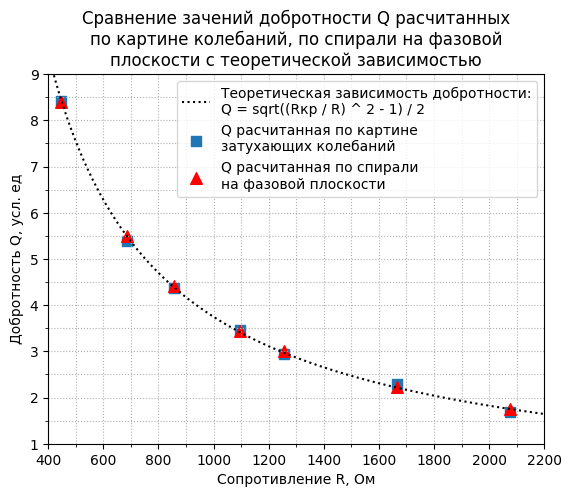

In [45]:
plt.plot(x, y, color='black', ls=':', label='Теоретическая зависимость добротности:\nQ = sqrt((Rкр / R) ^ 2 - 1) / 2 ')
plt.scatter(R, dobrPik, s=50, marker=',', label='Q расчитанная по картине\nзатухающих колебаний')
plt.scatter(R, dobrFaz, s=70, marker='^', label='Q расчитанная по спирали\nна фазовой плоскости', color='red')
ax = plt.gca()
ax.xaxis.set_minor_locator(ticker.MultipleLocator(100))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.5))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(1, 9)
plt.xlim(400, 2200)
plt.title('Сравнение зачений добротности Q расчитанных\nпо картине колебаний, по спирали на фазовой\nплоскости с теоретической зависимостью')
plt.xlabel("Сопротивление R, Ом")
plt.ylabel("Добротность Q, усл. ед")
ax.legend()
plt.show()

In [73]:
u01 = 1656
n0 = 60
u1 = np.array([444, 508, 572, 656, 764, 888, 1056, 1260, 1460, 1590, 1656, 1608, 1488, 1328, 1192, 1072, 976, 875, 808, 752, 704])/u01
n = np.array(list(range(50, 71)))/n0

x = np.linspace(min(n), max(n), 300)
spl1 = mis(n, u1, k=3)
y1 = spl1(x)

u02 = 904
u2 = np.array([408, 450, 496, 552, 606, 668, 728, 790, 840, 882, 904, 904, 888, 856, 824, 792, 752, 716, 676, 644, 612])/u02

spl2 = mis(n, u2, k=3)
y2 = spl2(x)

print(n)
print(u1)
print(u2)


[0.83333333 0.85       0.86666667 0.88333333 0.9        0.91666667
 0.93333333 0.95       0.96666667 0.98333333 1.         1.01666667
 1.03333333 1.05       1.06666667 1.08333333 1.1        1.11666667
 1.13333333 1.15       1.16666667]
[0.26811594 0.30676329 0.34541063 0.39613527 0.46135266 0.53623188
 0.63768116 0.76086957 0.88164251 0.96014493 1.         0.97101449
 0.89855072 0.80193237 0.71980676 0.647343   0.58937198 0.52838164
 0.48792271 0.45410628 0.42512077]
[0.45132743 0.49778761 0.54867257 0.61061947 0.67035398 0.73893805
 0.80530973 0.87389381 0.92920354 0.97566372 1.         1.
 0.98230088 0.94690265 0.91150442 0.87610619 0.83185841 0.7920354
 0.74778761 0.71238938 0.67699115]


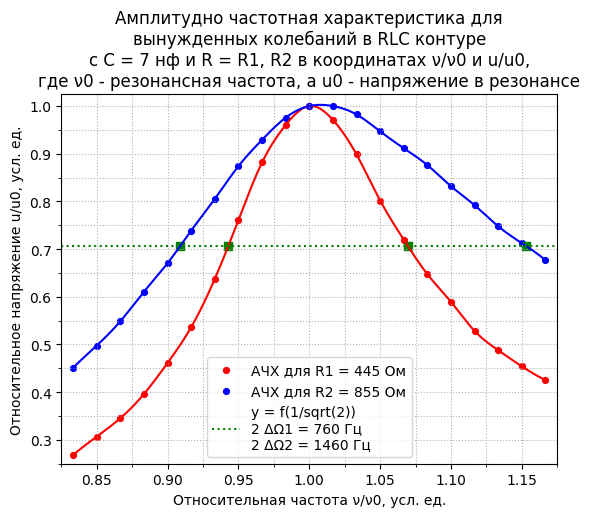

In [102]:
plt.plot(x, y1, color='red', ls='-')
plt.scatter(n, u1, color='red', s=70, marker='.', label='АЧХ для R1 = 445 Ом')

plt.plot(x, y2, color='blue', ls='-')
plt.scatter(n, u2, color='blue', s=70, marker='.', label='АЧХ для R2 = 855 Ом')

plt.plot([0.825, 1.175], [1/2**0.5, 1/2**0.5], color='green', ls=':', label=f'y = f(1/sqrt(2))\n2 ΔΩ1 = 760 Гц\n2 ΔΩ2 = 1460 Гц')
plt.scatter([0.942977, 1.0695877], spl1([0.942977, 1.0695877]), marker=',', color='green')
plt.scatter([0.9091, 1.153], spl2([0.9091, 1.153]), marker=',', color='green')
ax = plt.gca()
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.025))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.title('Амплитудно частотная характеристика для\nвынужденных колебаний в RLC контуре\nс C = 7 нф и R = R1, R2 в координатах ν/ν0 и u/u0,\nгде ν0 - резонансная частота, а u0 - напряжение в резонансе')
plt.xlabel("Относительная частота ν/ν0, усл. ед.")
plt.ylabel("Относительное напряжение u/u0, усл. ед.")
plt.ylim(0.25, 1.025)
plt.xlim(0.825, 1.175)
ax.legend()
plt.show()